In [ ]:
from google.colab import files
uploaded = files.upload()
FILE = list(uploaded.keys())[0]

Saving AQI.xlsx to AQI.xlsx


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_excel(FILE, sheet_name=0, engine="openpyxl")
df = df.rename(columns={"Ambient Temperature": "Temp", "ATOM PRESSURE": "Pressure",
                        "WINDSPEED": "Wind", "humidity": "Humidity",
                        "CARBON MONOOXIDE": "CO", "Nitrogen Dioxide concentration": "NO2",
                        "location": "Location"})
df["Datetime"] = pd.to_datetime(df["Datetime"])
df["Month"] = df["Datetime"].dt.month
df["Hour"] = df["Datetime"].dt.hour
df["DayName"] = df["Datetime"].dt.day_name()

(52560, 22)
0 missing values


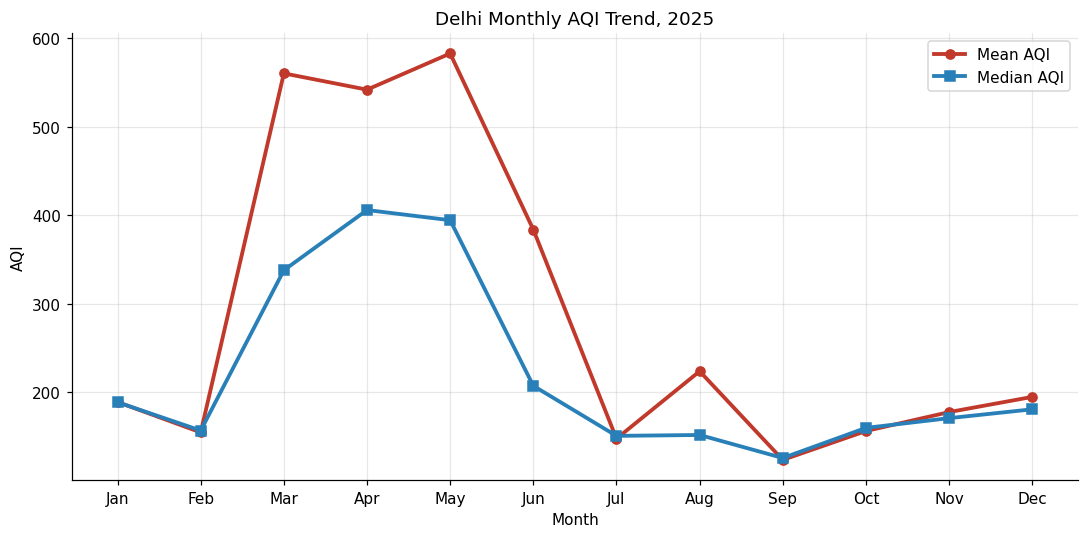

In [ ]:
bins   = [0, 50, 100, 200, 300, 400, np.inf]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["AQICategory"] = pd.cut(df["AQI"], bins=bins, labels=labels, include_lowest=True)

MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
CAT_COLORS = ["#00b050", "#92d050", "#ffd966", "#f4a460", "#e06666", "#7b1e1e"]

print(df.shape)
print(df.isna().sum().sum(), "missing values")
df[["AQI","PM 2.5","PM 10","CO","NO2","Temp","Humidity","Wind"]].describe().round(1)

# ------------------------------------------------------------
# 3. Monthly AQI trend (mean vs median)
monthly = df.groupby("Month")["AQI"].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(MONTHS, monthly["mean"], marker="o", lw=2.5, color="#c0392b", label="Mean AQI")
ax.plot(MONTHS, monthly["median"], marker="s", lw=2.5, color="#2980b9", label="Median AQI")
ax.set(title="Delhi Monthly AQI Trend, 2025", xlabel="Month", ylabel="AQI")
ax.legend(); plt.tight_layout(); plt.show()

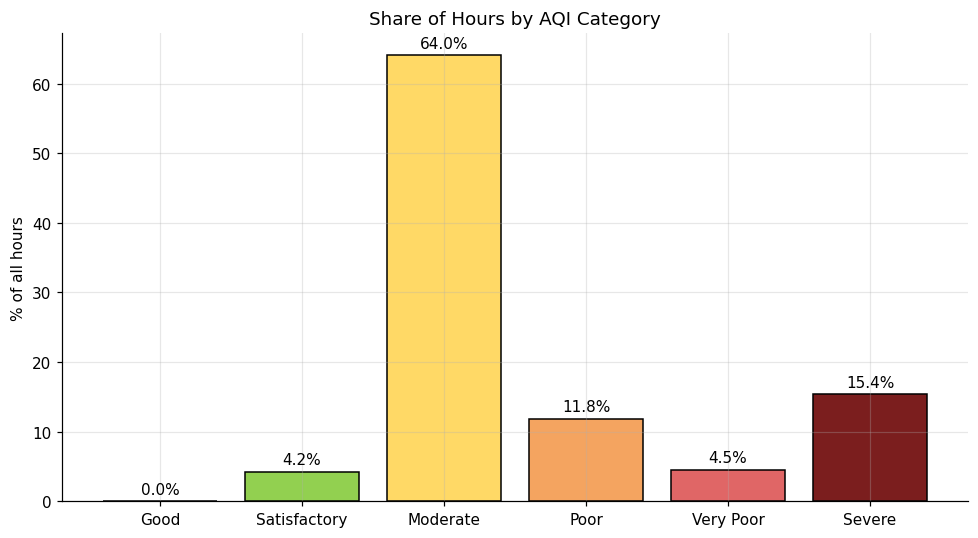

In [ ]:
share = (df["AQICategory"].value_counts(normalize=True).reindex(labels) * 100)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(share.index, share.values, color=CAT_COLORS, edgecolor="black")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(title="Share of Hours by AQI Category", ylabel="% of all hours")
plt.tight_layout(); plt.show()


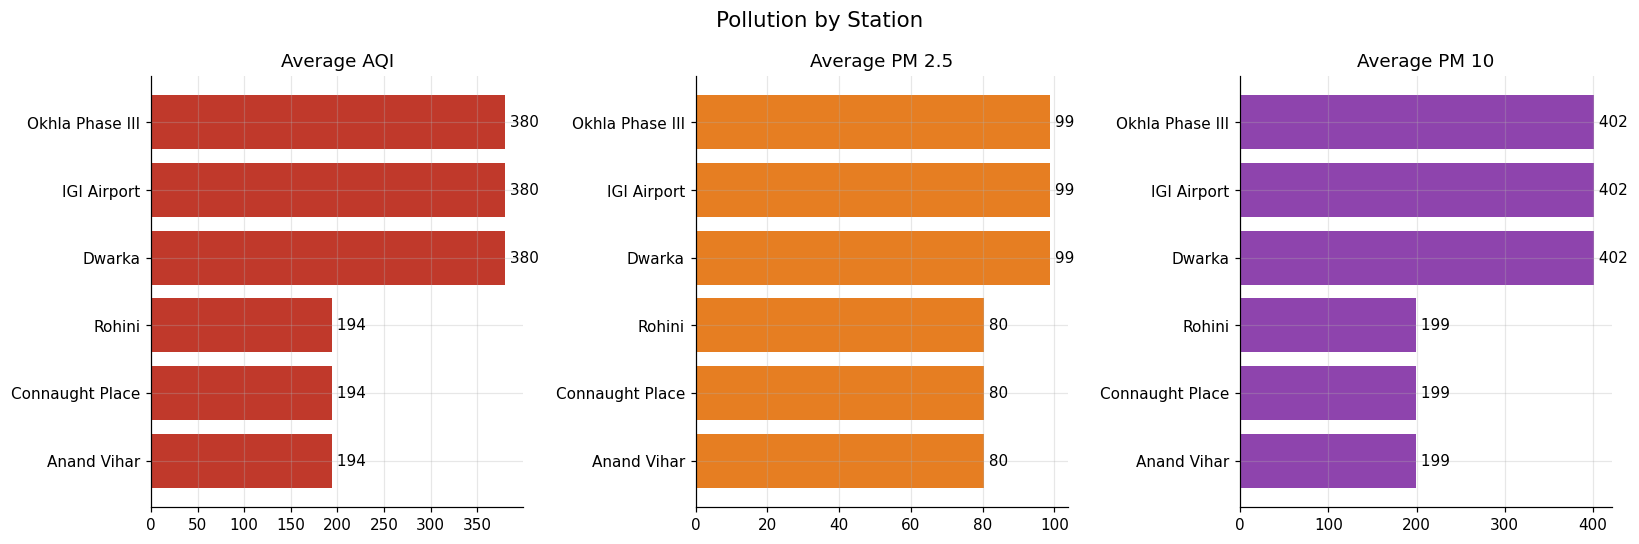

In [ ]:
loc = df.groupby("Location")[["AQI", "PM 2.5", "PM 10"]].mean().sort_values("AQI")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, c in zip(axes, loc.columns, ["#c0392b", "#e67e22", "#8e44ad"]):
    ax.barh(loc.index, loc[col], color=c)
    ax.set_title(f"Average {col}")
    for i, v in enumerate(loc[col]): ax.text(v, i, f" {v:.0f}", va="center")
plt.suptitle("Pollution by Station", fontsize=14); plt.tight_layout(); plt.show()

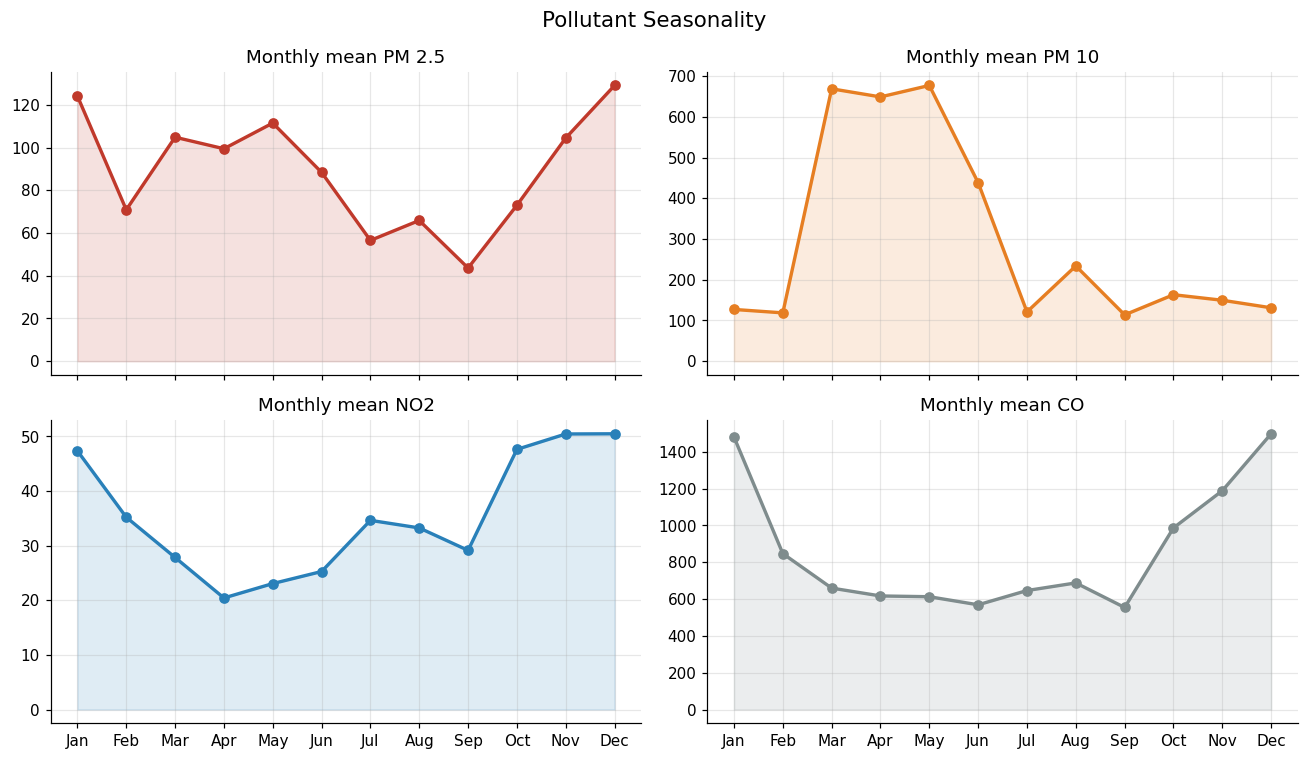

In [ ]:
pols = {"PM 2.5": "#c0392b", "PM 10": "#e67e22", "NO2": "#2980b9", "CO": "#7f8c8d"}
mp = df.groupby("Month")[list(pols)].mean()
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (p, c) in zip(axes.ravel(), pols.items()):
    ax.plot(MONTHS, mp[p], marker="o", color=c, lw=2.2)
    ax.fill_between(range(12), mp[p], alpha=0.15, color=c)
    ax.set_title(f"Monthly mean {p}")
plt.suptitle("Pollutant Seasonality", fontsize=14); plt.tight_layout(); plt.show()


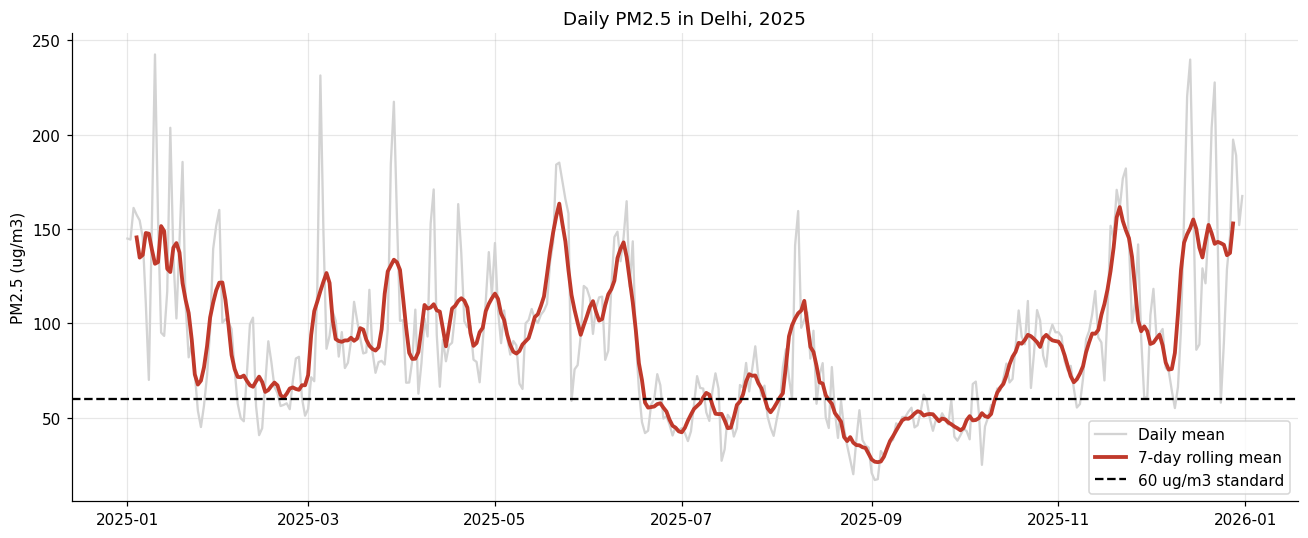

Days above 60 ug/m3: 263 of 365


In [ ]:
daily = df.groupby(df["Datetime"].dt.date)["PM 2.5"].mean()
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily.index, daily, color="lightgray", label="Daily mean")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color="#c0392b", lw=2.5, label="7-day rolling mean")
ax.axhline(60, color="black", ls="--", label="60 ug/m3 standard")
ax.set(title="Daily PM2.5 in Delhi, 2025", ylabel="PM2.5 (ug/m3)")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Days above 60 ug/m3: {(daily > 60).sum()} of {len(daily)}")


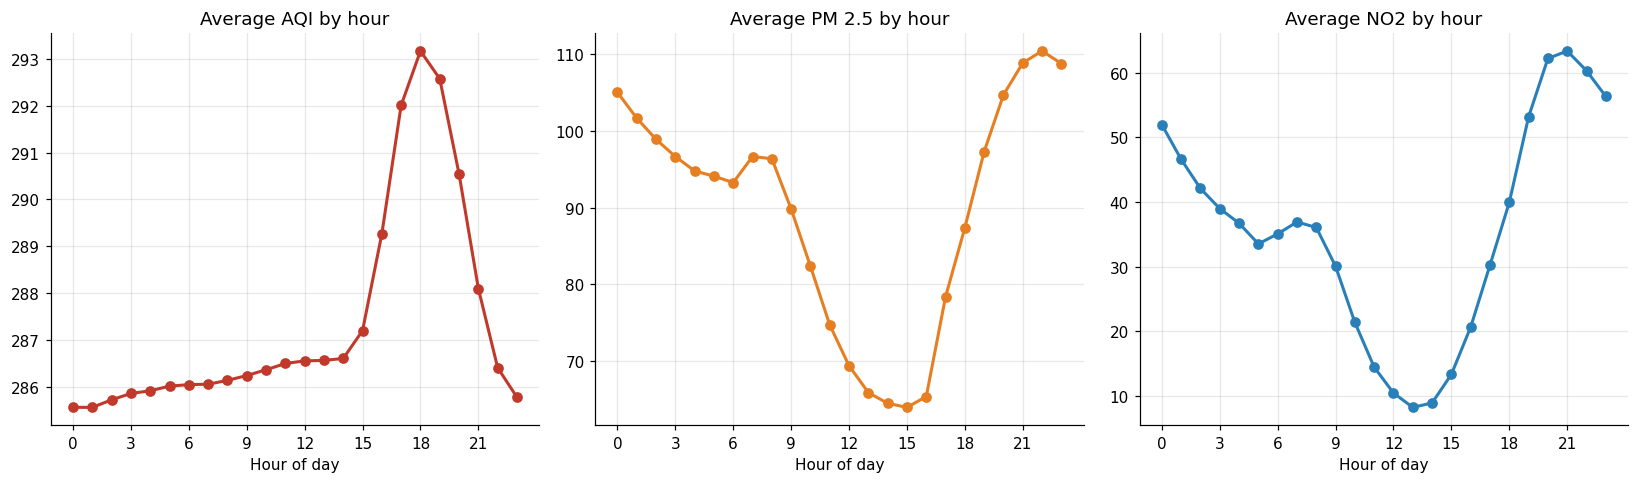

In [ ]:
hourly = df.groupby("Hour")[["AQI", "PM 2.5", "NO2"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, c in zip(axes, hourly.columns, ["#c0392b", "#e67e22", "#2980b9"]):
    ax.plot(hourly.index, hourly[col], marker="o", color=c, lw=2)
    ax.set(title=f"Average {col} by hour", xlabel="Hour of day", xticks=range(0, 24, 3))
plt.tight_layout(); plt.show()

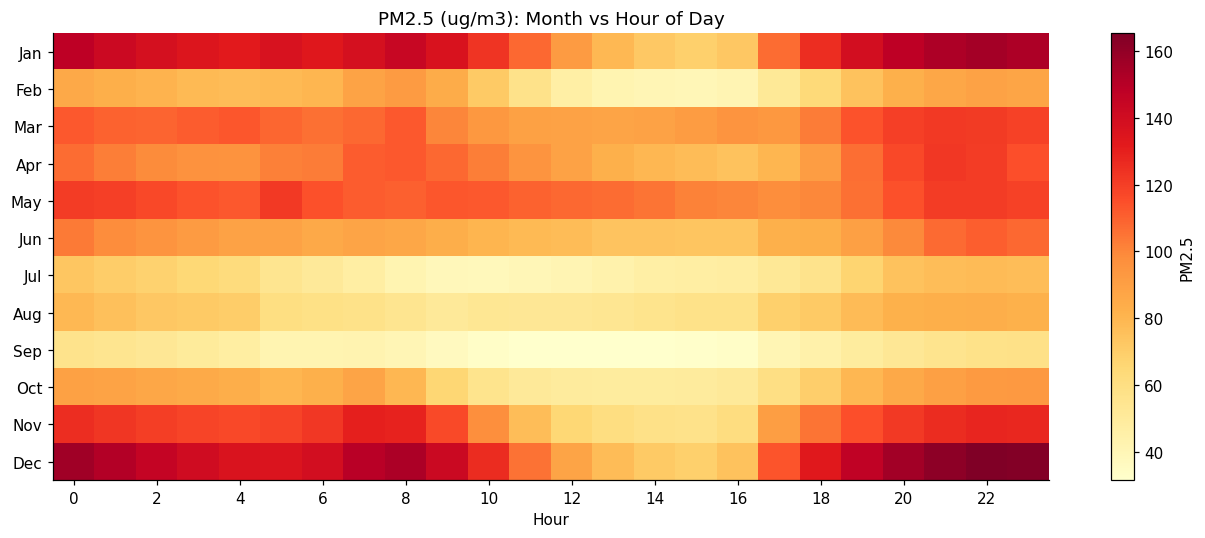

In [ ]:
pivot = df.pivot_table(values="PM 2.5", index="Month", columns="Hour", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd")
ax.set(xticks=range(0, 24, 2), yticks=range(12), yticklabels=MONTHS,
       title="PM2.5 (ug/m3): Month vs Hour of Day", xlabel="Hour")
ax.set_xticklabels(range(0, 24, 2)); ax.grid(False)
fig.colorbar(im, label="PM2.5"); plt.tight_layout(); plt.show()


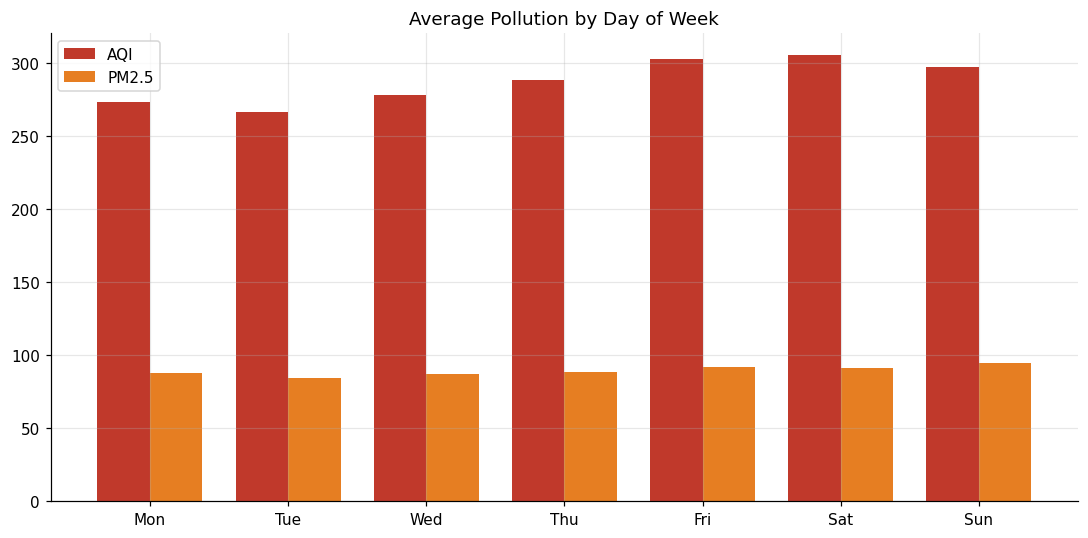

In [ ]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = df.groupby("DayName")[["AQI", "PM 2.5"]].mean().reindex(order)
x = np.arange(7); w = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, dow["AQI"], w, label="AQI", color="#c0392b")
ax.bar(x + w/2, dow["PM 2.5"], w, label="PM2.5", color="#e67e22")
ax.set_xticks(x); ax.set_xticklabels([d[:3] for d in order]); ax.set_title("Average Pollution by Day of Week")
ax.legend(); plt.tight_layout(); plt.show()


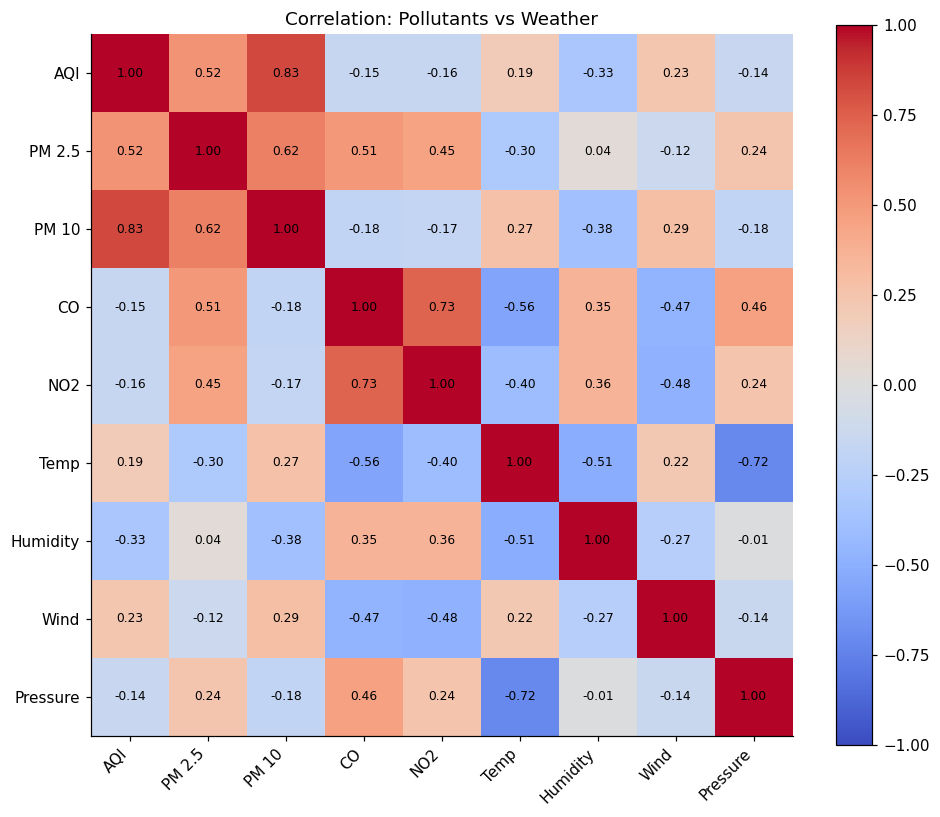

In [ ]:
cols = ["AQI", "PM 2.5", "PM 10", "CO", "NO2", "Temp", "Humidity", "Wind", "Pressure"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Correlation: Pollutants vs Weather"); plt.tight_layout(); plt.show()


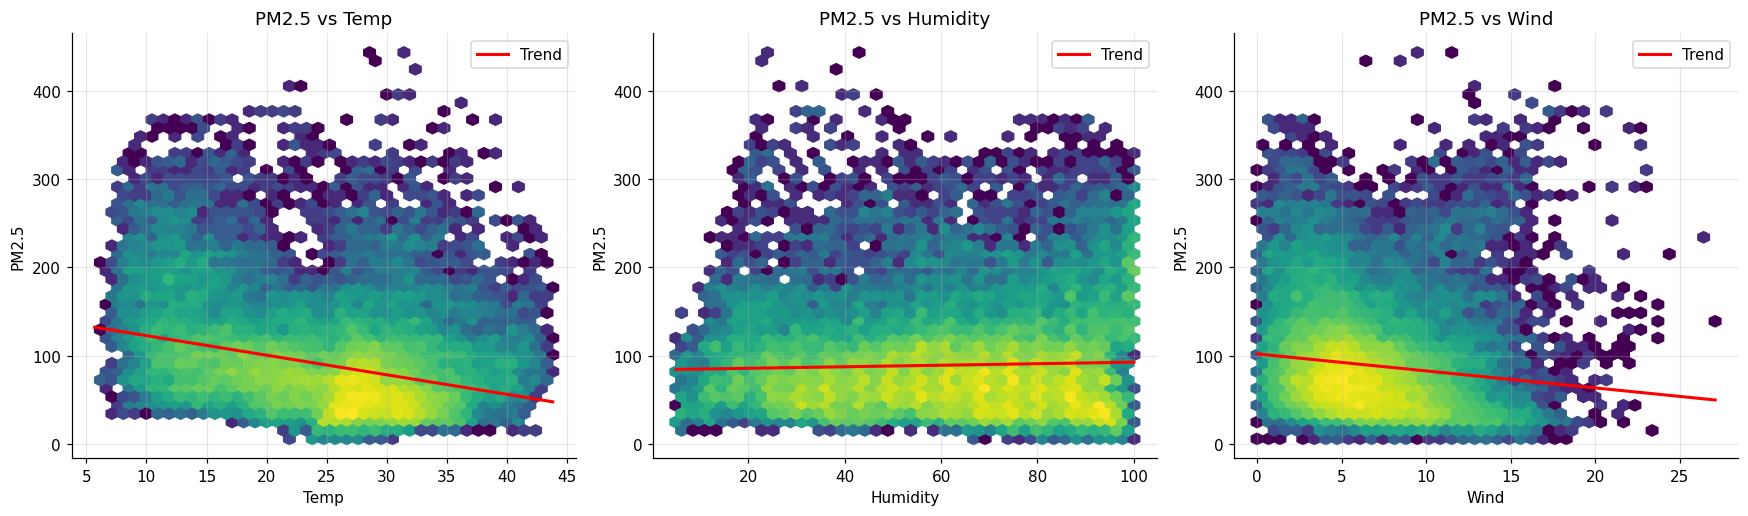

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, ["Temp", "Humidity", "Wind"]):
    hb = ax.hexbin(df[col], df["PM 2.5"], gridsize=40, cmap="viridis", mincnt=1, bins="log")
    m, b = np.polyfit(df[col], df["PM 2.5"], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 100)
    ax.plot(xs, m * xs + b, color="red", lw=2, label="Trend")
    ax.set(xlabel=col, ylabel="PM2.5", title=f"PM2.5 vs {col}"); ax.legend()
plt.tight_layout(); plt.show()

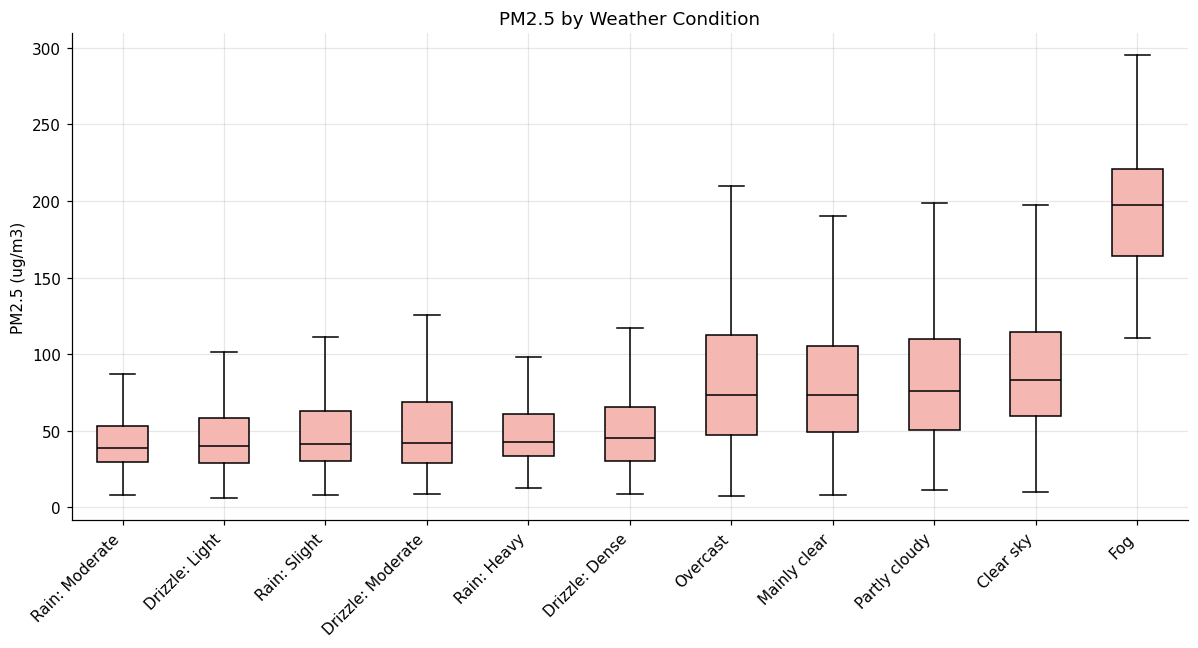

In [ ]:
med = df.groupby("Condition")["PM 2.5"].median().sort_values()
data = [df.loc[df["Condition"] == c, "PM 2.5"] for c in med.index]
fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(data, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#f5b7b1"), medianprops=dict(color="black"))
ax.set_xticks(range(1, len(med) + 1))
ax.set_xticklabels(med.index, rotation=45, ha="right")
ax.set(title="PM2.5 by Weather Condition", ylabel="PM2.5 (ug/m3)")
plt.tight_layout(); plt.show()


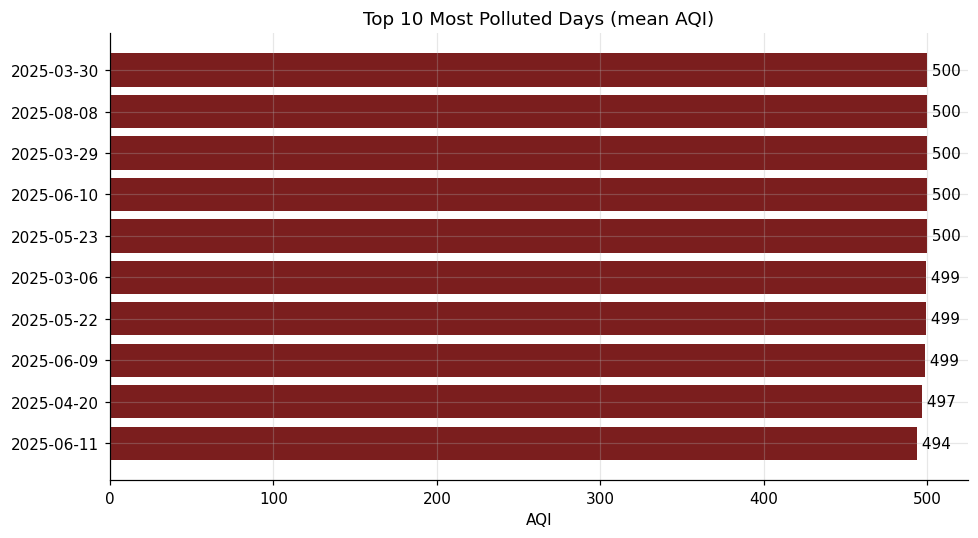

In [ ]:
d = df.assign(AQIcap=df["AQI"].clip(upper=500)).groupby(df["Datetime"].dt.date)["AQIcap"].mean()
top = d.nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([str(i) for i in top.index], top.values, color="#7b1e1e")
for i, v in enumerate(top.values): ax.text(v, i, f" {v:.0f}", va="center")
ax.set(title="Top 10 Most Polluted Days (mean AQI)", xlabel="AQI")
plt.tight_layout(); plt.show()


In [ ]:
print(f"Mean AQI: {df['AQI'].mean():.0f} | Median AQI: {df['AQI'].median():.0f}")
print(f"Hours rated Poor or worse: {(df['AQI'] > 200).mean()*100:.1f}%")
print(f"Worst month (mean AQI): {MONTHS[monthly['mean'].idxmax() - 1]}")
print(f"Best month (mean AQI):  {MONTHS[monthly['mean'].idxmin() - 1]}")
print(f"Peak hour for PM2.5: {hourly['PM 2.5'].idxmax()}:00")
print("Station AQI values:"); print(loc["AQI"].round(0).to_string())

Mean AQI: 287 | Median AQI: 170
Hours rated Poor or worse: 31.7%
Worst month (mean AQI): May
Best month (mean AQI):  Sep
Peak hour for PM2.5: 22:00
Station AQI values:
Location
Anand Vihar        194.0
Connaught Place    194.0
Rohini             194.0
Dwarka             380.0
IGI Airport        380.0
Okhla Phase III    380.0
